In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.sparse import csr_matrix

from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_validate,
)
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

In [22]:
from pathlib import Path

DATA_DIR = Path("../data/processed")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(train_df.shape)
print(test_df.shape)

train_df.head()

(8129, 3)
(2033, 3)


,text,label,source
0,Subject: enron methanol ; meter # : 988291\r\n...,ham,email
1,"Subject: hpl nom for january 9 , 2001\r\n( see...",ham,email
2,"Subject: neon retreat\r\nho ho ho , we ' re ar...",ham,email
3,"Subject: photoshop , windows , office . cheap ...",spam,email
4,Subject: looking for medication ? we ` re the ...,spam,email


In [23]:
X_train = train_df[["text", "source"]]
y_train = train_df["label"]

X_test = test_df[["text", "source"]]
y_test = test_df["label"]

## Baseline Model

In [24]:
X_train = train_df.drop(columns=["label"])
y_train = train_df["label"]

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score, pos_label="spam", zero_division=0
    ),
    "recall": make_scorer(
        recall_score, pos_label="spam", zero_division=0
    ),
    "f1": make_scorer(
        f1_score, pos_label="spam", zero_division=0
    ),
}

dummy = DummyClassifier(strategy="most_frequent")
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=123,
)

dummy_results = cross_validate(
    dummy,
    X_train,
    y_train,
    groups=X_train["text"],
    cv=cv,
    scoring=scoring,
    return_train_score=True,
)

pd.DataFrame(dummy_results).agg(["mean", "std"]).T

,mean,std
fit_time,0.001684,0.000084
score_time,0.010246,0.000977
test_accuracy,0.789519,0.000267
train_accuracy,0.789519,0.000067
test_precision,0.000000,0.000000
train_precision,0.000000,0.000000
test_recall,0.000000,0.000000
train_recall,0.000000,0.000000
test_f1,0.000000,0.000000
train_f1,0.000000,0.000000


## Linear Model

In [25]:
preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(ngram_range=(1, 2)), "text"),
    ("source", OneHotEncoder(handle_unknown="ignore"), ["source"]),
])

pipe = make_pipeline(preprocessor, LogisticRegression(max_iter=2000))

grid_search = GridSearchCV(
    pipe,
    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv,
    scoring=scoring,
    refit="f1",
    return_train_score=True,
)
grid_search.fit(X_train, y_train, groups=X_train["text"])

print(grid_search.best_params_)
print(f"Mean CV spam F1: {grid_search.best_score_:.3f}")

{'logisticregression__C': 100}
Mean CV spam F1: 0.951


## Other models

In [26]:
searches = {"Logistic regression": grid_search}

model_specs = {
    "Complement Naive Bayes": (
    ComplementNB(),
    {"complementnb__alpha": [0.01, 0.1, 0.5, 1.0, 5.0]},
),
    "Linear SVM": (
        LinearSVC(max_iter=5000, random_state=123),
        {"linearsvc__C": [0.001, 0.01, 0.1, 1, 10, 100]},
    ),
}

for name, (model, param_grid) in model_specs.items():
    search = GridSearchCV(
        make_pipeline(preprocessor, model),
        param_grid,
        cv=cv,
        scoring=scoring,
        refit="f1",
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=X_train["text"])
    searches[name] = search

results = pd.DataFrame([
    {
        "model": name,
        "spam F1": search.best_score_,
        "spam precision": search.cv_results_["mean_test_precision"][search.best_index_],
        "spam recall": search.cv_results_["mean_test_recall"][search.best_index_],
        "best params": search.best_params_,
    }
    for name, search in searches.items()
]).sort_values("spam F1", ascending=False)

initial_searches = searches.copy()

results

,model,spam F1,spam precision,spam recall,best params
2,Linear SVM,0.961475,0.975393,0.947987,{'linearsvc__C': 100}
0,Logistic regression,0.951133,0.969626,0.933381,{'logisticregression__C': 100}
1,Complement Naive Bayes,0.936030,0.923307,0.949159,{'complementnb__alpha': 0.01}


## Further hyperparameter optimization

In [27]:
preprocessor = ColumnTransformer([
    ("text", TfidfVectorizer(ngram_range=(1, 2)), "text"),
    ("source", OneHotEncoder(handle_unknown="ignore"), ["source"]),
])

pipe = make_pipeline(preprocessor, LogisticRegression(max_iter=2000))

grid_search = GridSearchCV(
    pipe,
    {"logisticregression__C": [10, 30, 100, 300, 1000]},
    cv=cv,
    scoring=scoring,
    refit="f1",
    return_train_score=True,
)
grid_search.fit(X_train, y_train, groups=X_train["text"])

print(grid_search.best_params_)
print(f"Mean CV spam F1: {grid_search.best_score_:.3f}")

searches = {"Logistic regression": grid_search}

model_specs = {
    "Complement Naive Bayes": (
    ComplementNB(),
    {"complementnb__alpha": [0.001, 0.003, 0.01, 0.03, 0.1]},
),
    "Linear SVM": (
        LinearSVC(max_iter=20000, random_state=123),
        {"linearsvc__C": [10, 30, 100, 300, 1000]},
    ),
}

for name, (model, param_grid) in model_specs.items():
    search = GridSearchCV(
        make_pipeline(preprocessor, model),
        param_grid,
        cv=cv,
        scoring=scoring,
        refit="f1",
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=X_train["text"])
    searches[name] = search

results = pd.DataFrame([
    {
        "model": name,
        "spam F1": search.best_score_,
        "spam precision": search.cv_results_["mean_test_precision"][search.best_index_],
        "spam recall": search.cv_results_["mean_test_recall"][search.best_index_],
        "best params": search.best_params_,
    }
    for name, search in searches.items()
]).sort_values("spam F1", ascending=False)

results

{'logisticregression__C': 100}
Mean CV spam F1: 0.951


,model,spam F1,spam precision,spam recall,best params
2,Linear SVM,0.961517,0.974253,0.949157,{'linearsvc__C': 300}
0,Logistic regression,0.951133,0.969626,0.933381,{'logisticregression__C': 100}
1,Complement Naive Bayes,0.946617,0.955403,0.938053,{'complementnb__alpha': 0.03}


## Linear SVM interpretation and feature importances

Positive weights push the decision score toward spam. Negative weights push it toward legitimate messages. The tables rank text features by their weights. For a specific message, each feature contributes its weight multiplied by its TF-IDF value. The email and SMS indicators contribute their full weights when active.

In [28]:
from IPython.display import display

best_svm = searches["Linear SVM"].best_estimator_
fitted_preprocessor = best_svm.named_steps["columntransformer"]
svm = best_svm.named_steps["linearsvc"]
spam_direction = 1 if svm.classes_[1] == "spam" else -1

feature_weights = pd.DataFrame({
    "feature": fitted_preprocessor.get_feature_names_out(),
    "weight toward spam": spam_direction * svm.coef_[0],
})
text_weights = feature_weights.iloc[fitted_preprocessor.output_indices_["text"]].copy()
text_weights["feature"] = text_weights["feature"].str.removeprefix("text__")
top_spam_terms = text_weights[text_weights["weight toward spam"] > 0].nlargest(10, "weight toward spam")
top_legitimate_terms = text_weights[text_weights["weight toward spam"] < 0].nsmallest(10, "weight toward spam")

print("Terms with the largest weights toward spam")
display(top_spam_terms.round(3).reset_index(drop=True))
print("Terms with the largest weights toward legitimate messages")
display(top_legitimate_terms.round(3).reset_index(drop=True))
print("Email and SMS indicator weights")
display(feature_weights.iloc[fitted_preprocessor.output_indices_["source"]].round(3).reset_index(drop=True))

Terms with the largest weights toward spam


,feature,weight toward spam
0,txt,3.452
1,text,2.710
2,uk,2.684
3,mobile,2.593
4,call,2.424
5,claim,2.404
6,free,2.230
7,150p,2.204
8,stop,2.175
9,http,2.136


Terms with the largest weights toward legitimate messages


,feature,weight toward spam
0,enron,-3.086
1,meter,-2.097
2,deal,-1.952
3,daren,-1.876
4,thanks,-1.767
5,2000,-1.693
6,attached,-1.650
7,gas,-1.643
8,2001,-1.571
9,at,-1.507


Email and SMS indicator weights


,feature,weight toward spam
0,source__source_email,0.430
1,source__source_sms,-0.687


## Results on the test set

Accuracy            0.9838
Precision (spam)    0.9720
Recall (spam)       0.9455
F1 (spam)           0.9586
dtype: float64

Selected model mean CV F1: 0.9615

              precision    recall  f1-score   support

  Legitimate     0.9866    0.9932    0.9899      1629
        Spam     0.9720    0.9455    0.9586       404

    accuracy                         0.9838      2033
   macro avg     0.9793    0.9694    0.9742      2033
weighted avg     0.9837    0.9838    0.9837      2033



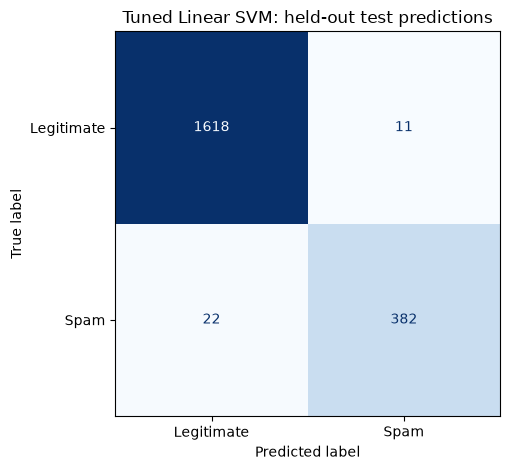

In [29]:
svm_search = searches["Linear SVM"]
final_model = svm_search.best_estimator_

X_test = test_df[["text", "source"]]
y_test = test_df["label"]
test_predictions = final_model.predict(X_test)

test_results = pd.Series({
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision (spam)": precision_score(
        y_test, test_predictions, pos_label="spam", zero_division=0
    ),
    "Recall (spam)": recall_score(
        y_test, test_predictions, pos_label="spam", zero_division=0
    ),
    "F1 (spam)": f1_score(
        y_test, test_predictions, pos_label="spam", zero_division=0
    ),
})

print(test_results.round(4))
print(f"\nSelected model mean CV F1: {svm_search.best_score_:.4f}\n")
print(classification_report(
    y_test,
    test_predictions,
    labels=["ham", "spam"],
    target_names=["Legitimate", "Spam"],
    digits=4,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    labels=["ham", "spam"],
    display_labels=["Legitimate", "Spam"],
    cmap="Blues",
    colorbar=False,
)
plt.title("Tuned Linear SVM: held-out test predictions")
plt.tight_layout()
plt.show()

,Actual label,Predicted label,Spam decision score,Intercept
0,ham,ham,-0.7717,-0.2569
1,ham,ham,-0.9992,-0.2569


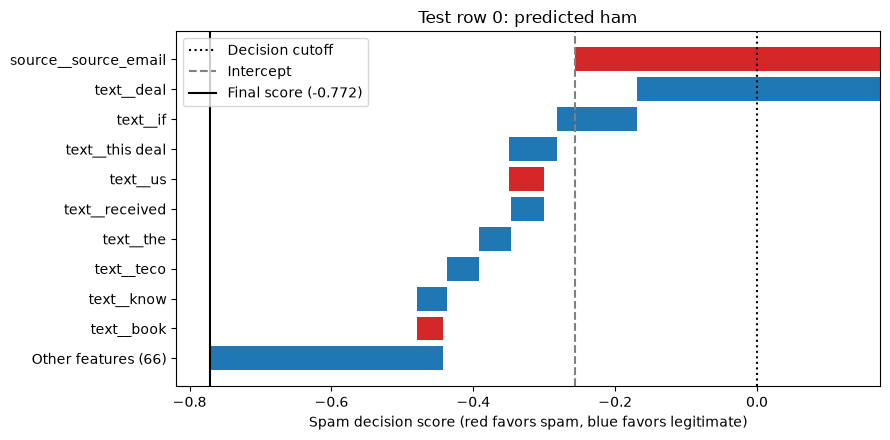

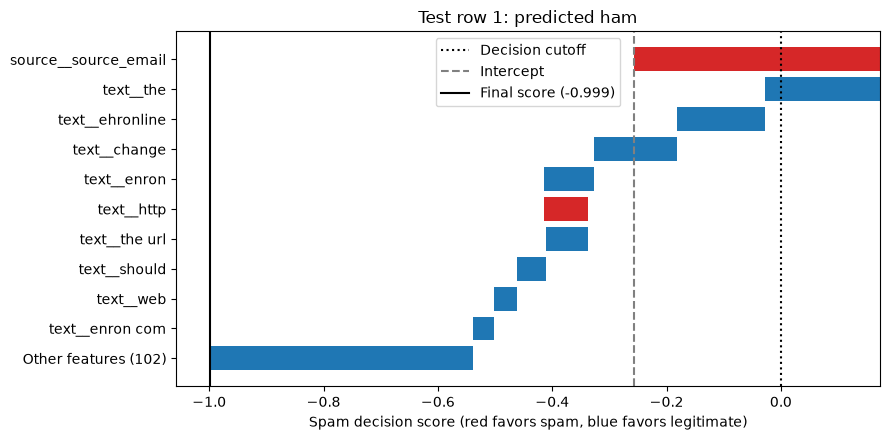

In [30]:
explanation_rows = X_test.iloc[:2]
preprocessor = final_model.named_steps["columntransformer"]
svm = final_model.named_steps["linearsvc"]

feature_names = preprocessor.get_feature_names_out()
encoded_rows = csr_matrix(preprocessor.transform(explanation_rows))

# Orient the score so positive values always favor spam.
spam_direction = 1 if svm.classes_[1] == "spam" else -1
weights = spam_direction * svm.coef_[0]
intercept = spam_direction * svm.intercept_[0]
decision_scores = spam_direction * final_model.decision_function(explanation_rows)

contributions = encoded_rows.multiply(weights).tocsr()
reconstructed_scores = intercept + np.asarray(contributions.sum(axis=1)).ravel()
np.testing.assert_allclose(reconstructed_scores, decision_scores, atol=1e-10)

example_results = pd.DataFrame({
    "Actual label": y_test.iloc[:2].to_numpy(),
    "Predicted label": test_predictions[:2],
    "Spam decision score": decision_scores,
    "Intercept": intercept,
}, index=explanation_rows.index)
display(example_results.round(4))

for i, row_index in enumerate(explanation_rows.index):
    row = contributions.getrow(i)
    row.eliminate_zeros()

    order = np.argsort(-np.abs(row.data))
    top, remaining = order[:10], order[10:]
    labels = feature_names[row.indices[top]].tolist()
    values = row.data[top].tolist()

    if remaining.size:
        labels.append(f"Other features ({remaining.size})")
        values.append(row.data[remaining].sum())

    steps = intercept + np.r_[0.0, np.cumsum(values)]
    colors = ["tab:red" if value > 0 else "tab:blue" for value in values]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    positions = np.arange(len(labels))
    ax.barh(positions, values, left=steps[:-1], color=colors)
    ax.set_yticks(positions, labels=labels)
    ax.invert_yaxis()

    ax.axvline(0, color="black", linestyle=":", label="Decision cutoff")
    ax.axvline(intercept, color="gray", linestyle="--", label="Intercept")
    ax.axvline(
        decision_scores[i],
        color="black",
        label=f"Final score ({decision_scores[i]:+.3f})",
    )

    ax.set_xlabel("Spam decision score (red favors spam, blue favors legitimate)")
    ax.set_title(f"Test row {row_index}: predicted {test_predictions[i]}")
    ax.legend()
    fig.tight_layout()
    plt.show()

## Summary

In [31]:
summary_rows = [{
    "Evaluation": "Baseline CV mean",
    "Model": "Dummy (most frequent)",
    "Best parameters": "—",
    "Accuracy": dummy_results["test_accuracy"].mean(),
    "Spam precision": dummy_results["test_precision"].mean(),
    "Spam recall": dummy_results["test_recall"].mean(),
    "Spam F1": dummy_results["test_f1"].mean(),
}]

metric_columns = {
    "accuracy": "Accuracy",
    "precision": "Spam precision",
    "recall": "Spam recall",
    "f1": "Spam F1",
}

for stage, stage_searches in [
    ("Initial tuning CV mean", initial_searches),
    ("Further tuning CV mean", searches),
]:
    for model_name, search in stage_searches.items():
        params = ", ".join(
            f"{key.rsplit('__', 1)[-1]}={value}"
            for key, value in search.best_params_.items()
        )
        summary_rows.append({
            "Evaluation": stage,
            "Model": model_name,
            "Best parameters": params,
            **{
                column: search.cv_results_[f"mean_test_{metric}"][search.best_index_]
                for metric, column in metric_columns.items()
            },
        })

svm_search = searches["Linear SVM"]
X_test = test_df[["text", "source"]]
y_test = test_df["label"]
test_predictions = svm_search.best_estimator_.predict(X_test)
spam_options = {"pos_label": "spam", "zero_division": 0}

summary_rows.append({
    "Evaluation": "Held-out test",
    "Model": "Linear SVM",
    "Best parameters": f"C={svm_search.best_params_['linearsvc__C']}",
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Spam precision": precision_score(y_test, test_predictions, **spam_options),
    "Spam recall": recall_score(y_test, test_predictions, **spam_options),
    "Spam F1": f1_score(y_test, test_predictions, **spam_options),
})

summary = pd.DataFrame(summary_rows)
print(summary.to_string(index=False, float_format="{:.4f}".format))

            Evaluation                  Model Best parameters  Accuracy  Spam precision  Spam recall  Spam F1
      Baseline CV mean  Dummy (most frequent)               —    0.7895          0.0000       0.0000   0.0000
Initial tuning CV mean    Logistic regression           C=100    0.9798          0.9696       0.9334   0.9511
Initial tuning CV mean Complement Naive Bayes      alpha=0.01    0.9727          0.9233       0.9492   0.9360
Initial tuning CV mean             Linear SVM           C=100    0.9840          0.9754       0.9480   0.9615
Further tuning CV mean    Logistic regression           C=100    0.9798          0.9696       0.9334   0.9511
Further tuning CV mean Complement Naive Bayes      alpha=0.03    0.9777          0.9554       0.9381   0.9466
Further tuning CV mean             Linear SVM           C=300    0.9840          0.9743       0.9492   0.9615
         Held-out test             Linear SVM           C=300    0.9838          0.9720       0.9455   0.9586


In [32]:
from pathlib import Path
import joblib

model_path = Path("../artifacts/spam_classifier_linear_svm.joblib")
model_path.parent.mkdir(parents=True, exist_ok=True)

final_model = searches["Linear SVM"].best_estimator_
joblib.dump(final_model, model_path)

['..\\artifacts\\spam_classifier_linear_svm.joblib']